# Modeling Pollution Spread in a River with the Diffusion Equation

**Course:** AIT 525

**Assignment:** Partial Differential Equations

**By:** Yashu Lanki

## Part 1: Introduction to PDEs and the Diffusion Equation

**Why a PDE?** Pollution in a river changes with both location and time. For example, at one spot on the river, the pollution level changes as time passes. At one moment in time, the pollution level is different at different spots along the river. Because the pollution level depends on two independent inputs, location (x) and time (t), it is described by a *partial* differential equation instead of an ordinary one.

**PDEs in AI.** PDEs matter for dynamic systems because they describe how things change over time, so if we know the starting state, we can predict the future (Nelson, 2023). In image processing, pixel brightness spreads into neighboring pixels, and AI uses this to remove noise and sharpen blurry images (Perona & Malik, 1990). In weather prediction, heat and moisture spread across the map over time, and AI uses this to predict weather faster (Lam et al., 2023).

**The diffusion equation.** For our river, the diffusion equation is:

$$\frac{\partial u}{\partial t} = D\,\frac{\partial^2 u}{\partial x^2}$$

- **u(x, t)** is the pollution concentration at location x along the river and time t.
- **x** is the location along the river, and **t** is time.
- **∂u/∂t** is how fast the pollution at one spot changes over time.
- **∂²u/∂x²** measures how different a spot is from its neighbors. A sharp peak, like a spill, has a large value.
- **D** is the diffusion coefficient. A large D spreads pollution fast, and a small D spreads it slowly.

Right after a spill, the pollution level at the peak goes down while its neighbors go up, so the spill flattens and spreads out over time (Nelson, 2023).

**Type of PDE.** The diffusion equation is a second-order PDE, because its highest derivative is ∂²u/∂x². It is also *linear*, because u and its derivatives are never squared or multiplied together, and *parabolic*, the family of PDEs that smooth things out over time (Strauss, 2008).

## Part 2: Numerical Methods for Solving the Diffusion Equation

**Problem setup.** A chemical spill happens in the middle of a 10 km stretch of river. The model tracks how the pollution spreads along the river over time.

| Setting | Value | Meaning |
|---|---|---|
| River length (L) | 10 km | The stretch of river being modeled |
| Grid points (nx) | 101 | One point every 0.1 km |
| Diffusion coefficient (D) | 0.1 km²/hour | How fast the pollution mixes into nearby water (an assumed value for a slow river) |
| Initial condition, u(x, 0) | A narrow bell-shaped peak of 100 mg/L at x = 5 km | The spill right after it happens, with zero pollution everywhere else |
| Boundary conditions | u(0, t) = 0 and u(10, t) = 0 | Both ends stay clean, because fresh water flows in and polluted water flows out |

Because the ends stay at zero, the **steady state** is a clean river: u = 0 everywhere. This model only includes the spreading (diffusion) part of the problem. A real river also carries pollution downstream with the current, which would add another term to the equation.

**The explicit finite difference method.** A computer cannot work with smooth curves directly, so the river is split into points spaced Δx apart, and time moves forward in small steps of Δt. Each derivative is replaced by a difference between nearby points (LeVeque, 2007):

$$\frac{\partial u}{\partial t} \approx \frac{u_i^{n+1} - u_i^{n}}{\Delta t}, \qquad \frac{\partial^2 u}{\partial x^2} \approx \frac{u_{i+1}^{n} - 2u_i^{n} + u_{i-1}^{n}}{\Delta x^2}$$

Here i is the point along the river and n is the time step. Putting these into the diffusion equation and solving for the new value gives the update rule:

$$u_i^{n+1} = u_i^{n} + r\,\left(u_{i+1}^{n} - 2u_i^{n} + u_{i-1}^{n}\right), \qquad r = \frac{D\,\Delta t}{\Delta x^2}$$

- The part in parentheses compares a point with its two neighbors. If a point has more pollution than its neighbors, it goes down. If it has less, it goes up.
- The method is called **explicit** because each new value is calculated directly from the old values, one time step at a time.
- The method is only **stable** when r ≤ 0.5. If r is larger, small errors grow at every step and the solution blows up (LeVeque, 2007). This notebook uses r = 0.4.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

# River and grid
L = 10              # river length (km)
nx = 101            # number of grid points
D = 0.1             # diffusion coefficient (km^2/hour)
x = np.linspace(0, L, nx)
dx = x[1] - x[0]    # 0.1 km between points

# Time step chosen so that r = 0.4 (stable, since r <= 0.5)
r = 0.4
dt = r * dx**2 / D  # 0.04 hours (2.4 minutes)

# Initial condition: a narrow bell-shaped spill of 100 mg/L at the middle of the river
spill_center, spill_width = 5, 0.2
u0 = 100 * np.exp(-(x - spill_center)**2 / (2 * spill_width**2))

# Boundary conditions: both ends of the river stay clean
u0[0] = u0[-1] = 0

print(f'dx = {dx:.2f} km, dt = {dt:.2f} hours, r = {D * dt / dx**2:.2f}')

dx = 0.10 km, dt = 0.04 hours, r = 0.40


In [2]:
def solve_fd(u0, r, n_steps):
    # Explicit finite difference method. Returns the river at every time step.
    u = u0.copy()
    history = [u.copy()]
    for _ in range(n_steps):
        u_new = u.copy()
        u_new[1:-1] = u[1:-1] + r * (u[2:] - 2 * u[1:-1] + u[:-2])
        u_new[0] = u_new[-1] = 0   # ends stay clean
        u = u_new
        history.append(u.copy())
    return np.array(history)

t_end = 500                             # hours (about 3 weeks)
n_steps = int(round(t_end / dt))
history = solve_fd(u0, r, n_steps)
times = np.arange(n_steps + 1) * dt

print(f'{n_steps:,} time steps, {history.shape[1]} points along the river')

12,500 time steps, 101 points along the river


**Visualization 1: The spill at different times.** Each line shows the pollution along the river at one moment.

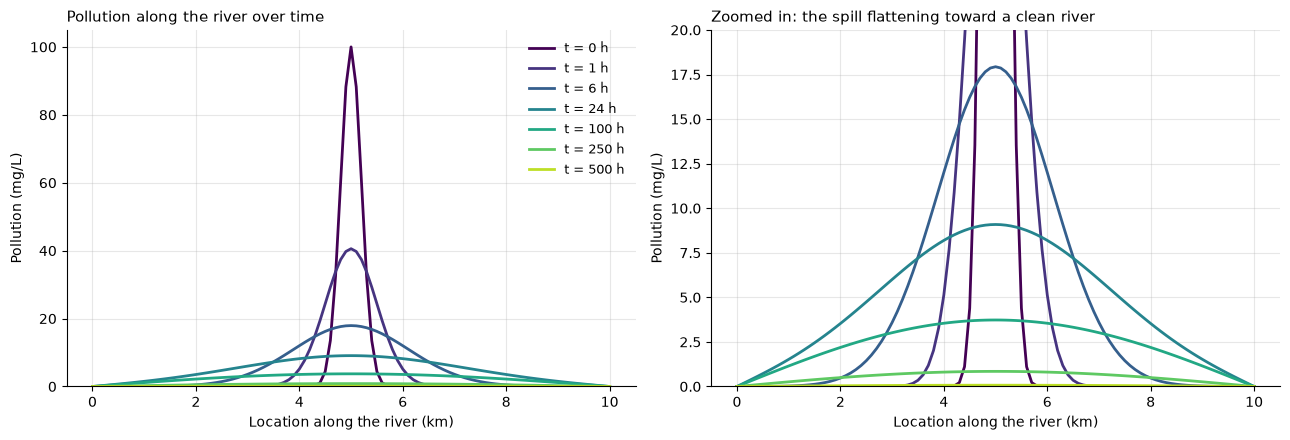

t =   0 h: peak = 100.00 mg/L
t =   1 h: peak =  40.58 mg/L
t =   6 h: peak =  17.94 mg/L
t =  24 h: peak =   9.09 mg/L
t = 100 h: peak =   3.73 mg/L
t = 250 h: peak =   0.85 mg/L
t = 500 h: peak =   0.07 mg/L


In [3]:
def step_at(hours):
    return int(round(hours / dt))

snapshot_hours = [0, 1, 6, 24, 100, 250, 500]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(snapshot_hours)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, ylim in zip(axes, [(0, 105), (0, 20)]):
    for color, h in zip(colors, snapshot_hours):
        ax.plot(x, history[step_at(h)], color=color, linewidth=2, label=f't = {h} h')
    ax.set_xlabel('Location along the river (km)')
    ax.set_ylabel('Pollution (mg/L)')
    ax.set_ylim(*ylim)
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_title('Pollution along the river over time', loc='left', fontsize=11)
axes[1].set_title('Zoomed in: the spill flattening toward a clean river', loc='left', fontsize=11)
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

for h in snapshot_hours:
    print(f't = {h:>3} h: peak = {history[step_at(h)].max():6.2f} mg/L')

**Reading the plot.** At t = 0, the spill is a tall, narrow peak at 5 km. Within the first hour the peak drops to less than half its height, because it is so much higher than its neighbors. After that the spreading slows down: the curve gets wider and flatter, and pollution starts to leave through the clean ends of the river. By 500 hours the river is almost clean. This matches Part 1: the peak goes down and the neighbors go up.

**Visualization 2: Convergence to the steady state.** The left plot tracks the highest pollution level and the total amount of pollution left in the river. The right plot shows how much the river changes from one time step to the next. When that change gets close to zero, the solution has *converged*. Both use a log scale, so each grid line is 10 times smaller than the one above it.

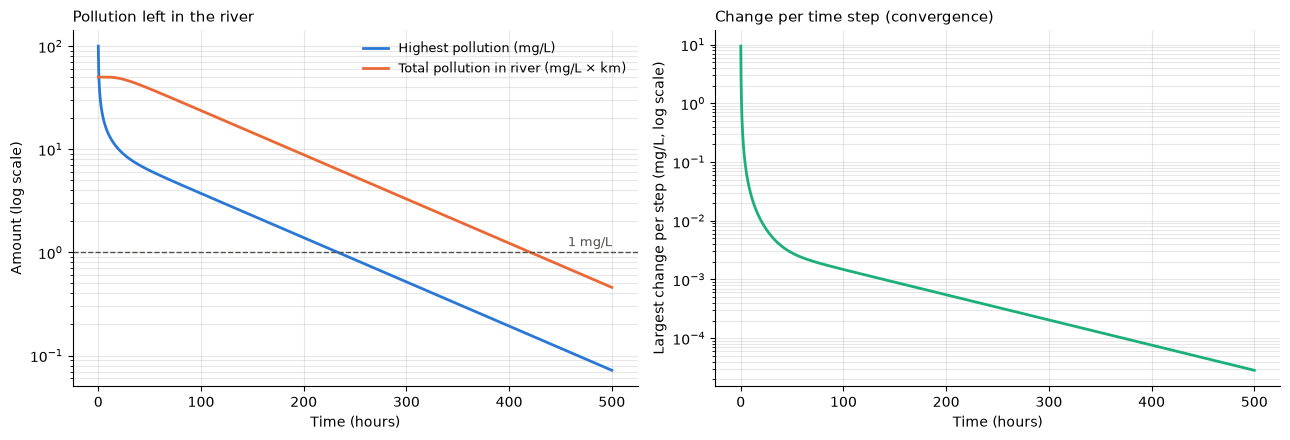

Total pollution at start: 50.1, after 500 h: 0.46
Peak falls below 1 mg/L after 233 hours
Peak falls below 0.1 mg/L after 467 hours


In [4]:
peak = history.max(axis=1)
total = history.sum(axis=1) * dx                     # total pollution in the river (mg/L x km)
change = np.abs(np.diff(history, axis=0)).max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].semilogy(times, peak, color='#2a78d6', linewidth=2, label='Highest pollution (mg/L)')
axes[0].semilogy(times, total, color='#eb6834', linewidth=2, label='Total pollution in river (mg/L × km)')
axes[0].axhline(1, color='#52514e', linestyle='--', linewidth=1)
axes[0].text(t_end, 1.15, '1 mg/L', ha='right', fontsize=9, color='#52514e')
axes[0].set_title('Pollution left in the river', loc='left', fontsize=11)
axes[0].set_ylabel('Amount (log scale)')

axes[1].semilogy(times[1:], change, color='#1baf7a', linewidth=2)
axes[1].set_title('Change per time step (convergence)', loc='left', fontsize=11)
axes[1].set_ylabel('Largest change per step (mg/L, log scale)')

for ax in axes:
    ax.set_xlabel('Time (hours)')
    ax.grid(alpha=0.3, which='both')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

print(f'Total pollution at start: {total[0]:.1f}, after 500 h: {total[-1]:.2f}')
print(f'Peak falls below 1 mg/L after {times[np.argmax(peak < 1)]:.0f} hours')
print(f'Peak falls below 0.1 mg/L after {times[np.argmax(peak < 0.1)]:.0f} hours')

**Reading the convergence plot.** For the first day, the total amount of pollution stays almost the same, because the spill is only spreading and has not reached the ends yet. After that, pollution leaves through the clean ends, and both lines fall in a straight line on the log scale, which means they shrink by the same fraction every hour. The highest level drops below 1 mg/L after about 233 hours (about 10 days) and below 0.1 mg/L after about 467 hours. The change per step also falls toward zero, which shows the solution is converging to the steady state of a clean river.

**Why r must be ≤ 0.5.** The cell below runs the same spill with r = 0.6, which breaks the stability rule.

In [5]:
unstable = solve_fd(u0, 0.6, 300)
print(f'r = 0.6 after 300 steps: highest value = {np.abs(unstable[-1]).max():.2e} mg/L')
print(f'r = 0.4 after 300 steps: highest value = {history[300].max():.2f} mg/L')

r = 0.6 after 300 steps: highest value = 6.17e+36 mg/L
r = 0.4 after 300 steps: highest value = 12.79 mg/L


With r = 0.6, the "pollution" grows to an impossibly large number instead of spreading out. Each step overshoots, the error flips sign and gets bigger, and the result is meaningless. This is the main weakness of the explicit method: the time step must stay small. *Implicit* methods such as Crank–Nicolson stay stable with larger time steps, but they have to solve a system of equations at every step (Crank & Nicolson, 1947).

## Part 3: Applying Mathematical Transforms to Solve PDEs

**The simplified problem.** For the Fourier method, the river is treated as **very long** (no ends), with the same spill in the middle. This is a good match for the first several hours, before the pollution reaches the ends of the 10 km stretch.

**The idea.** Any shape, including the spill, can be built by adding together waves of different frequencies (Fourier, 1822/1878). Smooth, wide shapes are made mostly of low frequencies, and sharp details need high frequencies. The Fourier transform rewrites the pollution as "how much of each frequency k it contains."

**Step-by-step solution.**

1. **Transform.** Apply the Fourier transform to u(x, t) in space:
$$\hat{u}(k, t) = \int_{-\infty}^{\infty} u(x, t)\, e^{-ikx}\, dx$$

2. **Derivatives become multiplication.** Taking a derivative in x turns into multiplying by ik in the frequency domain, so the second derivative becomes:
$$\frac{\partial^2 u}{\partial x^2} \;\longrightarrow\; (ik)^2\,\hat{u} = -k^2\,\hat{u}$$

3. **The PDE becomes a simple ODE.** The diffusion equation turns into a separate, easy equation for each frequency k:
$$\frac{d\hat{u}}{dt} = -D\,k^2\,\hat{u}$$

4. **Solve in the frequency domain.** Each frequency simply shrinks exponentially over time:
$$\hat{u}(k, t) = \hat{u}(k, 0)\, e^{-D k^2 t}$$
High frequencies (large k) shrink much faster than low ones. That is why sharp peaks disappear quickly and the curve becomes smooth.

5. **Inverse transform.** Convert back to the river:
$$u(x, t) = \frac{1}{2\pi}\int_{-\infty}^{\infty} \hat{u}(k, t)\, e^{ikx}\, dk$$

In code, NumPy's Fast Fourier Transform (`np.fft.fft` and `np.fft.ifft`) performs steps 1 and 5 on the grid points (Cooley & Tukey, 1965; Harris et al., 2020).

**Exact answer to check against.** For a bell-shaped spill on a very long river, these steps can be done by hand, and the answer is another bell shape that gets wider and shorter over time (Strauss, 2008):
$$u(x, t) = 100\,\frac{\sigma_0}{\sigma(t)}\,\exp\!\left(-\frac{(x - 5)^2}{2\,\sigma(t)^2}\right), \qquad \sigma(t)^2 = \sigma_0^2 + 2Dt$$
where σ₀ = 0.2 km is the starting width of the spill.

In [6]:
k = 2 * np.pi * np.fft.fftfreq(nx, d=dx)    # frequency of each wave (radians per km)
u0_hat = np.fft.fft(u0)                     # Step 1: transform the spill

def solve_fourier(t):
    u_hat = u0_hat * np.exp(-D * k**2 * t)  # Step 4: shrink each frequency
    return np.real(np.fft.ifft(u_hat))      # Step 5: transform back to the river

def exact_solution(t):
    width_sq = spill_width**2 + 2 * D * t
    return 100 * spill_width / np.sqrt(width_sq) * np.exp(-(x - spill_center)**2 / (2 * width_sq))

**The spill in the frequency domain.** This plot shows how much of each frequency the spill contains, at different times. Only positive frequencies are shown, because the negative ones are a mirror image.

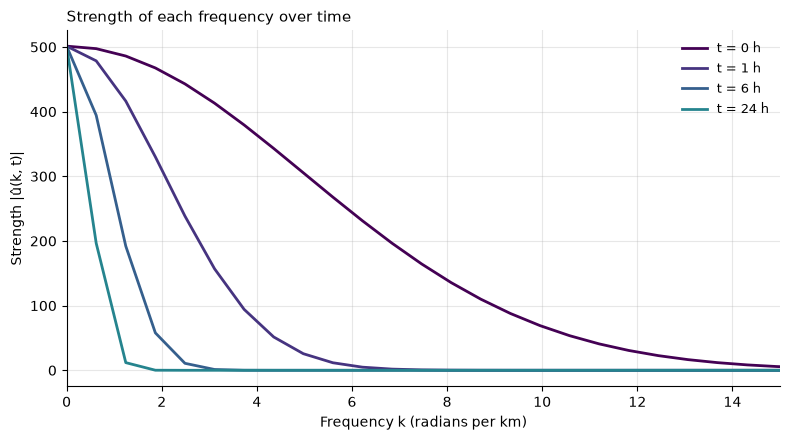

In [7]:
order = np.argsort(k)
positive = k[order] >= 0

fig, ax = plt.subplots(figsize=(8, 4.5))
for color, h in zip(colors, [0, 1, 6, 24]):
    strength = np.abs(u0_hat * np.exp(-D * k**2 * h))[order]
    ax.plot(k[order][positive], strength[positive], color=color, linewidth=2, label=f't = {h} h')
ax.set_title('Strength of each frequency over time', loc='left', fontsize=11)
ax.set_xlabel('Frequency k (radians per km)')
ax.set_ylabel('Strength |û(k, t)|')
ax.set_xlim(0, 15)
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

**Reading the frequency plot.** At t = 0, the narrow spill contains a wide range of frequencies. After 1 hour, the high frequencies are almost gone, and by 24 hours only the lowest frequencies are left. Diffusion acts like a filter that removes sharp detail first, which is the same idea used to smooth noise out of images (Perona & Malik, 1990).

**Comparing the two methods.** Both methods are compared with the exact answer at 1, 6, and 12 hours, while the spill is still far from the ends of the river.

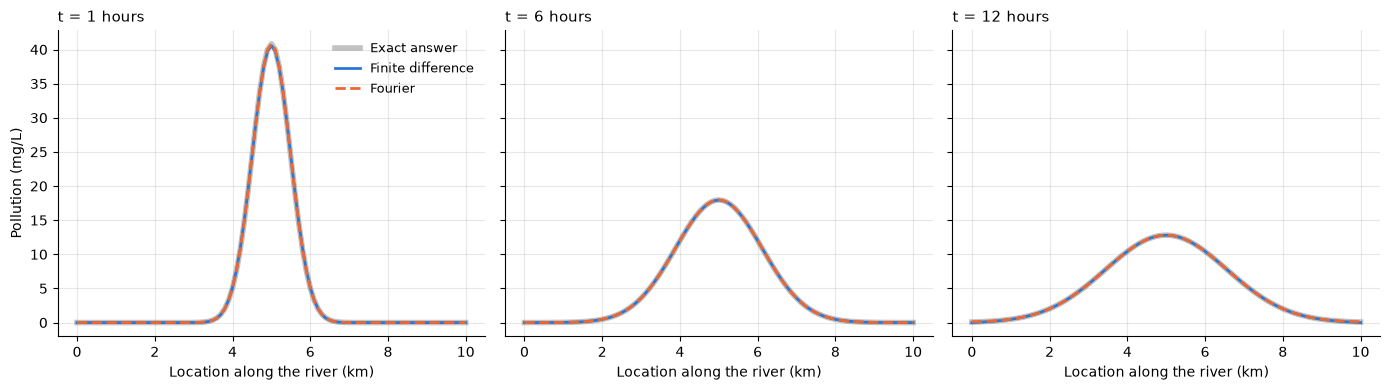

t =  1 h: largest error, finite difference = 0.2493 mg/L, Fourier = 0.0000 mg/L
t =  6 h: largest error, finite difference = 0.0245 mg/L, Fourier = 0.0005 mg/L
t = 12 h: largest error, finite difference = 0.0763 mg/L, Fourier = 0.0620 mg/L

Time to reach t = 12 h: finite difference = 0.536 ms (300 steps), Fourier = 0.007 ms (1 step)


In [8]:
compare_hours = [1, 6, 12]

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, h in zip(axes, compare_hours):
    ax.plot(x, exact_solution(h), color='#52514e', linewidth=4, alpha=0.35, label='Exact answer')
    ax.plot(x, history[step_at(h)], color='#2a78d6', linewidth=2, label='Finite difference')
    ax.plot(x, solve_fourier(h), color='#eb6834', linewidth=2, linestyle='--', label='Fourier')
    ax.set_title(f't = {h} hours', loc='left', fontsize=11)
    ax.set_xlabel('Location along the river (km)')
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Pollution (mg/L)')
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

for h in compare_hours:
    exact = exact_solution(h)
    fd_error = np.abs(history[step_at(h)] - exact).max()
    fourier_error = np.abs(solve_fourier(h) - exact).max()
    print(f't = {h:>2} h: largest error, finite difference = {fd_error:.4f} mg/L, Fourier = {fourier_error:.4f} mg/L')

# Speed: time to compute the river at t = 12 hours
start = time.perf_counter()
for _ in range(100):
    solve_fd(u0, r, step_at(12))
fd_ms = (time.perf_counter() - start) / 100 * 1000

start = time.perf_counter()
for _ in range(100):
    solve_fourier(12)
fourier_ms = (time.perf_counter() - start) / 100 * 1000

print(f'\nTime to reach t = 12 h: finite difference = {fd_ms:.3f} ms ({step_at(12)} steps), Fourier = {fourier_ms:.3f} ms (1 step)')

**Reading the comparison.** All three curves sit on top of each other. At 1 hour, the Fourier result matches the exact answer almost perfectly (error close to zero), while the finite difference method is off by about 0.25 mg/L, because replacing derivatives with differences adds a small error. By 12 hours, both methods differ slightly from the exact answer, for different reasons. The finite difference method holds the river ends at zero, and the Fourier method treats the river as a loop, so pollution leaving one end comes back in the other. The exact answer assumes a river with no ends. The Fourier method is also much faster: it jumps straight to any time in one step, while the finite difference method has to take 300 small steps to reach 12 hours.

## Fourier Transform vs. Numerical Methods

**Advantages of the Fourier transform**
- **Exact for simple problems.** It solves each frequency exactly, so the only error comes from the grid, not from approximating derivatives. In this notebook it matched the exact answer almost perfectly at 1 hour.
- **Fast.** It can jump directly to any time with one transform and one inverse transform, instead of hundreds of small steps, and it has no stability limit on the time step.
- **Easy to understand.** It shows *why* diffusion smooths things out: high frequencies shrink fastest.

**Limitations of the Fourier transform**
- **Simple shapes only.** It needs simple boundaries (a very long river or a loop) and a constant diffusion coefficient. Here it treated the river as a loop, so it could never show pollution leaving through clean ends.
- **Only linear equations.** It works because each frequency evolves on its own. Real problems often have a D that changes along the river, a current, or chemical reactions, and then the frequencies mix and the method no longer applies directly.

**Advantages and limitations of the finite difference method**
- **Flexible.** It handles any starting shape, any boundary condition (like the clean ends used in Part 2), a D that changes from place to place, and extra terms such as the river current, with only small changes to the code.
- **Approximate and step-limited.** Its answer has a small error that depends on Δx and Δt, and the explicit version must keep r ≤ 0.5, which forces many small time steps on a fine grid.

**When a Fourier or Laplace transform is more appropriate**
- **Fourier transform:** when the problem is linear, has constant coefficients, and has a very long or repeating (periodic) domain. Examples are smoothing or filtering images, or checking a numerical solver against an exact answer.
- **Laplace transform:** when the problem starts at t = 0 and has inputs that change over time, such as a factory pipe that leaks into the river at a steady rate from one end. The Laplace transform works on the *time* variable and turns ∂u/∂t into s·U − u(x, 0), which builds the initial condition directly into the equation (Strauss, 2008).
- **Numerical methods:** for everything else, including irregular shapes, changing coefficients, and nonlinear equations, which covers most real-world problems.

**In AI applications.** The two approaches are now being combined. Fourier Neural Operators learn to solve PDEs by working in the frequency domain, which makes them fast and accurate on weather and fluid-flow problems (Li et al., 2021). Physics-informed neural networks take the opposite route and learn a solution that satisfies the PDE at many sample points, much like a numerical method (Raissi et al., 2019).

## Conclusion

This project modeled a chemical spill spreading along a 10 km river with the one-dimensional diffusion equation. The explicit finite difference method showed the full story with clean river ends. The spill's peak dropped from 100 mg/L to about 41 mg/L in the first hour, and the river converged to a clean steady state, with the peak falling below 1 mg/L after about 10 days. The Fourier transform solved a simplified version, a river with no ends. It matched the exact answer almost perfectly and reached any time in a single step, and it showed that diffusion removes sharp, high-frequency detail first.

**Key findings**

| | Finite difference (explicit) | Fourier transform |
|---|---|---|
| Accuracy | Small error from approximating derivatives (about 0.25 mg/L at 1 hour) | Almost exact for the simplified problem |
| Speed | Hundreds of small time steps (r ≤ 0.5) | One step to any time |
| Boundaries | Any, such as the clean river ends | Only very long or repeating domains |
| Real-world flexibility | High: changing D, currents, nonlinear terms | Low: linear, constant-coefficient problems only |

**PDEs in industry.** PDEs let engineers and scientists *simulate* a process before it happens, instead of waiting to measure it. Environmental agencies use diffusion models to plan responses to spills, and weather services use PDE-based models to forecast storms. AI models such as GraphCast now learn from these simulations to make forecasts much faster (Lam et al., 2023), and diffusion-based image tools use the same smoothing idea seen in this notebook. Faster, cheaper simulations mean better decisions in less time, which is a major source of efficiency and innovation in industry.

## References

Cooley, J. W., & Tukey, J. W. (1965). An algorithm for the machine calculation of complex Fourier series. *Mathematics of Computation, 19*(90), 297–301. https://doi.org/10.1090/S0025-5718-1965-0178586-1

Crank, J., & Nicolson, P. (1947). A practical method for numerical evaluation of solutions of partial differential equations of the heat-conduction type. *Mathematical Proceedings of the Cambridge Philosophical Society, 43*(1), 50–67. https://doi.org/10.1017/S0305004100023197

Fourier, J. (1878). *The analytical theory of heat* (A. Freeman, Trans.). Cambridge University Press. (Original work published 1822)

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature, 585*(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Lam, R., Sanchez-Gonzalez, A., Willson, M., Wirnsberger, P., Fortunato, M., Alet, F., Ravuri, S., Ewalds, T., Eaton-Rosen, Z., Hu, W., Merose, A., Hoyer, S., Holland, G., Vinyals, O., Stott, J., Pritzel, A., Mohamed, S., & Battaglia, P. (2023). Learning skillful medium-range global weather forecasting. *Science, 382*(6677), 1416–1421. https://doi.org/10.1126/science.adi2336

LeVeque, R. J. (2007). *Finite difference methods for ordinary and partial differential equations: Steady-state and time-dependent problems*. Society for Industrial and Applied Mathematics. https://doi.org/10.1137/1.9780898717839

Li, Z., Kovachki, N., Azizzadenesheli, K., Liu, B., Bhattacharya, K., Stuart, A., & Anandkumar, A. (2021). Fourier neural operator for parametric partial differential equations. In *International Conference on Learning Representations*. https://arxiv.org/abs/2010.08895

Nelson, H. (2023). *Essential math for AI: Next-level mathematics for efficient and successful AI systems*. O'Reilly Media.

Perona, P., & Malik, J. (1990). Scale-space and edge detection using anisotropic diffusion. *IEEE Transactions on Pattern Analysis and Machine Intelligence, 12*(7), 629–639. https://doi.org/10.1109/34.56205

Raissi, M., Perdikaris, P., & Karniadakis, G. E. (2019). Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations. *Journal of Computational Physics, 378*, 686–707. https://doi.org/10.1016/j.jcp.2018.10.045

Strauss, W. A. (2008). *Partial differential equations: An introduction* (2nd ed.). Wiley.